[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch08-mini_workbook.ipynb)

# One attention layer on `the cat sat`

The three words `the`, `cat`, `sat` have four numbers each. With three
learned matrices, each word has a query, a key and a value of width 3. One
word's query dotted with every key gives that word's scores; divided by √3,
the scores give its weights through a softmax, and the weighted average of the
values is its new vector. How much of the weight of `the` lies on `cat`, and
which weights are 0 under a causal mask?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

WORDS = ["the", "cat", "sat"]
# The toy of the ch08 lecture, pp. 13 to 16 (claim_8_1 in figures/data/claim-instances.json): invented numbers.
X = np.array([[1, 0, 1, 0], [0, 2, 0, 2], [1, 1, 1, 1]])
WQ = np.array([[1, 0, 1], [1, 0, 0], [0, 0, 1], [0, 1, 1]])
WK = np.array([[0, 0, 1], [1, 1, 0], [0, 1, 0], [1, 1, 0]])
WV = np.array([[0, 2, 0], [0, 3, 0], [1, 0, 3], [1, 1, 0]])
D_K = 3
# One row per position, added to the word at that position: invented numbers of width 4.
POS_TABLE = np.array([[0, 1, 0, 0], [1, 0, 0, 1], [0, 0, 2, 0]])
plt.rcParams.update({"xtick.labelsize": 9, "ytick.labelsize": 9})


def softmax(s):  # e to each score, divided by the sum: weights with a sum of 1
    e = np.exp(np.asarray(s, dtype=float) - np.max(s))
    return e / e.sum()


def fmt(v):  # a row of numbers to two places
    return ", ".join(f"{t:.2f}" for t in v)


def layer(x, causal=False):  # weights A and output rows Z of one attention layer over the rows of x
    s = (x @ WQ) @ (x @ WK).T / np.sqrt(D_K)
    if causal:  # scores of later words set to minus infinity before the softmax
        s = np.where(np.tril(np.ones_like(s)) == 1, s, -np.inf)
    a = np.array([softmax(r) for r in s])
    return a, a @ (x @ WV)


def attention_row(word):  # scores, weights, output row of one word; the weights as bars
    i = WORDS.index(word)
    s = (X @ WK) @ (X[i] @ WQ)
    a, z = layer(X)
    print("query  :", tuple(int(t) for t in X[i] @ WQ))
    print("scores :", ", ".join(f"{w} {v}" for w, v in zip(WORDS, s)))
    print("scaled :", ", ".join(f"{w} {v / np.sqrt(D_K):.3f}" for w, v in zip(WORDS, s)))
    print("weights:", ", ".join(f"{w} {v:.3f}" for w, v in zip(WORDS, a[i])))
    print("output :", "(" + fmt(z[i]) + ")")
    fig, ax = plt.subplots(figsize=(4.2, 2.6), layout="constrained")
    bars = ax.bar(WORDS, a[i], color=["#a6192e" if np.isclose(v, a[i].max()) else "#9e9e9e" for v in a[i]])
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in a[i]], fontsize=9)
    ax.set(ylim=(0, 1), ylabel="weight", title=f"weights of {word} over the cat sat")
    plt.show()


def weight_grid(causal):  # the three rows of weights; masked cells in grey
    a, _ = layer(X, causal)
    fig, ax = plt.subplots(figsize=(3.8, 3.3), layout="constrained")
    ax.set_facecolor("#eeeeee")
    ax.imshow(np.where(np.tril(np.ones((3, 3))) == 1, a, np.nan) if causal else a, cmap="Reds", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            masked = causal and j > i
            ax.text(j, i, "masked" if masked else f"{a[i, j]:.3f}", ha="center", va="center", fontsize=9,
                    color="#9e9e9e" if masked else ("white" if a[i, j] > 0.6 else "black"))
    ax.set(xticks=range(3), xticklabels=WORDS, yticks=range(3), yticklabels=WORDS,
           title="causal mask" if causal else "no mask")
    ax.set_xlabel("weight on", fontsize=9)
    ax.set_ylabel("row of", fontsize=9)
    plt.show()
    print("row sums:", ", ".join(f"{v:.3f}" for v in a.sum(axis=1)))


def word_order(order):  # output rows of one layer for the words in this order, without and with the position table
    x = X[[WORDS.index(w) for w in order]]
    grids = [("no position table", layer(x)[1]), ("position table added", layer(x + POS_TABLE)[1])]
    top = max(z.max() for _, z in grids)
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.6), layout="constrained")
    for ax, (title, z) in zip(axes, grids):
        ax.imshow(z, cmap="Blues", vmin=0, vmax=top)
        for i in range(3):
            for j in range(3):
                ax.text(j, i, f"{z[i, j]:.2f}", ha="center", va="center", fontsize=9,
                        color="white" if z[i, j] > 0.6 * top else "black")
        ax.set(xticks=[], yticks=range(3), yticklabels=[f"{k + 1}: {w}" for k, w in enumerate(order)], title=title)
    plt.show()


def score_bars(scores=None):  # softmax weights of (0, 1, 0), of the same scores times 4, of the student's scores
    rows = [[0, 1, 0], [0, 4, 0]]
    if scores is not None and list(scores) not in rows:
        rows.append(list(scores))
    fig, ax = plt.subplots(figsize=(4.8, 2.7), layout="constrained")
    for n, r in enumerate(rows):
        w = softmax(r)
        bars = ax.bar(np.arange(3) + 0.27 * (n - (len(rows) - 1) / 2), w, 0.27,
                      color=["#9e9e9e", "#a6192e", "#000000"][n], label=str(tuple(r)))
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in w], fontsize=8)
    ax.set(xticks=range(3), xticklabels=WORDS, ylim=(0, 1.12), ylabel="weight")
    ax.legend(fontsize=8, title="scores", title_fontsize=8, loc="upper left")
    plt.show()

## 1. Scores, weights, one output row for `the`

The query of `the` is dotted with the three keys. The scores are divided by
√3, and a softmax gives three weights with a sum of 1; the output row of `the`
is the weighted average of the three value rows. Run the cell: how much of the
weight of `the` lies on `cat`? Then set `WORD` to `"cat"` and run it again:
how much weight has `cat` on itself?

query  : (1, 0, 2)
scores : the 2, cat 4, sat 4
scaled : the 1.155, cat 2.309, sat 2.309
weights: the 0.136, cat 0.432, sat 0.432
output : (1.86, 6.32, 1.70)


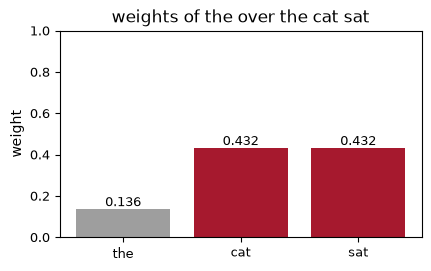

In [2]:
WORD = "the"
attention_row(WORD)

### Solution

In [3]:
a, z = layer(X)
s_cat = (X @ WK) @ (X[1] @ WQ) / np.sqrt(D_K)
display(Markdown(f"`the` has {a[0, 1]:.3f} of its weight on `cat`, {a[0, 2]:.3f} on `sat` and {a[0, 0]:.3f} on itself; its "
                 f"output row is ({fmt(z[0])}). `cat` has {a[1, 1]:.3f} on itself, {a[1, 2]:.3f} on `sat` and "
                 f"{a[1, 0]:.3f} on `the`. Its scaled scores, {s_cat[0]:.3f}, {s_cat[1]:.3f}, {s_cat[2]:.3f}, lie further "
                 f"apart: a gap of {s_cat[1] - s_cat[2]:.2f} is a factor of {np.exp(s_cat[1] - s_cat[2]):.1f} between two weights."))

`the` has 0.432 of its weight on `cat`, 0.432 on `sat` and 0.136 on itself; its output row is (1.86, 6.32, 1.70). `cat` has 0.909 on itself, 0.090 on `sat` and 0.001 on `the`. Its scaled scores, 2.309, 9.238, 6.928, lie further apart: a gap of 2.31 is a factor of 10.1 between two weights.

## 2. The causal mask on `the cat sat`

A model trained on the next word has, at each position, weight on that word
and the words before it alone. Under the causal mask, the scores of later
words are set to minus infinity before the softmax: their weights are 0, and
each row still has a sum of 1. Run the cell: which weights are 0? Then set
`CAUSAL` to `False` and run it again: how much of the weight of `cat` lies on
`sat` without the mask?

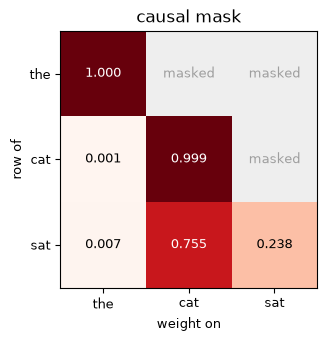

row sums: 1.000, 1.000, 1.000


In [4]:
CAUSAL = True
weight_grid(CAUSAL)

### Solution

In [5]:
masked, _ = layer(X, causal=True)
full, _ = layer(X)
display(Markdown(f"Under the mask, `the` has all of its weight on itself, {masked[0, 0]:.3f}, and `cat` has "
                 f"{masked[1, 0]:.3f} on `the`, {masked[1, 1]:.3f} on itself: the three weights above the diagonal are 0. "
                 f"Without the mask, `cat` has {full[1, 2]:.3f} on `sat`, a word after it, and {full[1, 1]:.3f} on itself. "
                 "The row of `sat` is the same in both grids: " + ", ".join(f"{v:.3f}" for v in full[2]) + "."))

Under the mask, `the` has all of its weight on itself, 1.000, and `cat` has 0.001 on `the`, 0.999 on itself: the three weights above the diagonal are 0. Without the mask, `cat` has 0.090 on `sat`, a word after it, and 0.909 on itself. The row of `sat` is the same in both grids: 0.007, 0.755, 0.238.

## 3. Swapped words, swapped output rows

Without a position signal, a word has the same output row at every position:
with two words swapped, their output rows are swapped and unchanged. With a
position table, row k of the table is added to the word at position k. The
left grid has the output rows without the table, the right grid with it. Run
the cell, then set `ORDER` to `["sat", "cat", "the"]` and run it again: in
which grid are the rows of `the` the same as before?

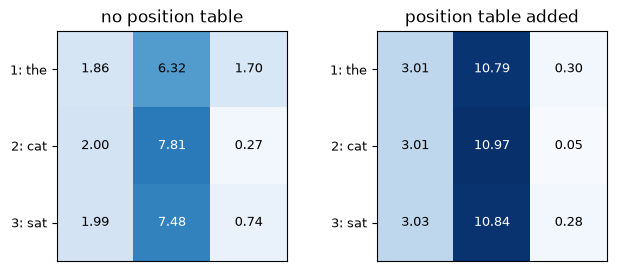

In [6]:
ORDER = ["the", "cat", "sat"]
word_order(ORDER)

### Solution

In [7]:
swapped = X[[2, 1, 0]]
z_plain, z_swap = layer(X)[1], layer(swapped)[1]
p_plain, p_swap = layer(X + POS_TABLE)[1], layer(swapped + POS_TABLE)[1]
display(Markdown(f"Without the table, `the` has the output row ({fmt(z_plain[0])}) at position 1 and ({fmt(z_swap[2])}) "
                 f"at position 3: the same row, in a new place. With the table, `the` has ({fmt(p_plain[0])}) at "
                 f"position 1 and ({fmt(p_swap[2])}) at position 3: one word, two vectors. With the table, the output "
                 "depends on the order of the words."))

Without the table, `the` has the output row (1.86, 6.32, 1.70) at position 1 and (1.86, 6.32, 1.70) at position 3: the same row, in a new place. With the table, `the` has (3.01, 10.79, 0.30) at position 1 and (2.77, 10.17, 1.06) at position 3: one word, two vectors. With the table, the output depends on the order of the words.

## Appendix. Scores times 4: the division by √d_k

A softmax gives each word e^s over the sum of e^s in its row. The bars are the
weights of the scores (0, 1, 0) and of the same scores times 4, (0, 4, 0).
A sum of d_k products of spread 1 has a spread of √d_k, so undivided scores
grow with the width of the query, and the weight of a row lies on one word.
Divided by √d_k, the scores have a spread near 1.

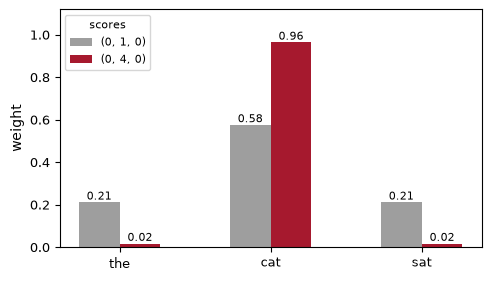

In [8]:
score_bars()

**Exercise.** Set `SCORES` to `[0, 2, 0]`, then to the undivided scores of
`cat`, `[4, 16, 12]`. What weight has the middle word each time?

scores [0, 1, 0]: weights 0.212, 0.576, 0.212


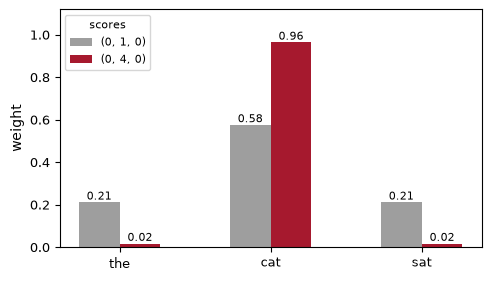

In [9]:
SCORES = [0, 1, 0]
print(f"scores {SCORES}: weights " + ", ".join(f"{v:.3f}" for v in softmax(SCORES)))
score_bars(SCORES)

### Solution

In [10]:
a, _ = layer(X)
display(Markdown(f"The scores (0, 2, 0) give the middle word {softmax([0, 2, 0])[1]:.2f}: e² is {np.exp(2):.2f}, against "
                 f"1 for each other word. The undivided scores of `cat`, (4, 16, 12), give `cat` "
                 f"{softmax([4, 16, 12])[1]:.3f} of its weight, against {a[1, 1]:.3f} after the division by √3."))

The scores (0, 2, 0) give the middle word 0.79: e² is 7.39, against 1 for each other word. The undivided scores of `cat`, (4, 16, 12), give `cat` 0.982 of its weight, against 0.909 after the division by √3.